# Calibración de Segmentación PDI 
Utiliza este cuaderno para ajustar interactivamente el umbral de binarización sin procesar todo el video continuo.

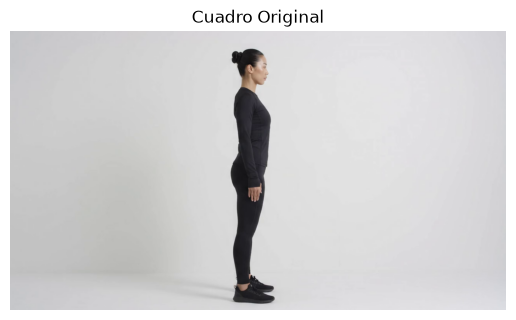

In [3]:
import cv2
import matplotlib.pyplot as plt
from m2_segmentacion import segmentar_sujeto

# 1. Cargar el primer cuadro del video de prueba 
cap = cv2.VideoCapture('sentadilla1.mp4')
ret, frame = cap.read()
cap.release() 
 
if ret: 
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    plt.imshow(frame_rgb) 
    plt.title('Cuadro Original') 
    plt.axis('off') 
    plt.show() 
else: 
    print('Error: No se pudo cargar el video. Verifica la ruta.')

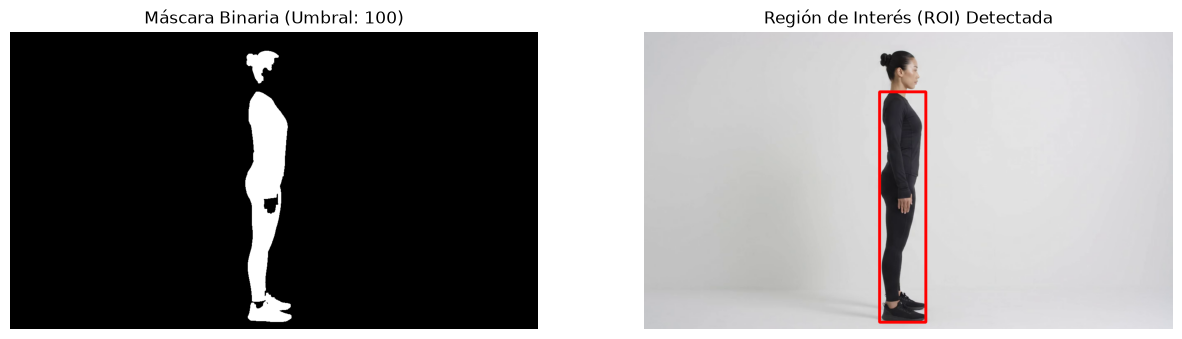

In [4]:
# 2. Prueba manual de umbral 
UMBRAL = 100 # Modifica este número (0 a 255) y vuelve a ejecutar la celda 
 
if ret: 
    mascara, bbox = segmentar_sujeto(frame_rgb, UMBRAL) 
     
    plt.figure(figsize=(15, 6)) 
     
    # Mostrar la máscara binaria 
    plt.subplot(1, 2, 1) 
    plt.imshow(mascara, cmap='gray') 
    plt.title(f'Máscara Binaria (Umbral: {UMBRAL})') 
    plt.axis('off') 
     
    # Mostrar la ROI superpuesta 
    frame_roi = frame_rgb.copy() 
    if bbox: 
        x, y, w, h = bbox 
        cv2.rectangle(frame_roi, (x, y), (x+w, y+h), (255, 0, 0), 5) 
     
    plt.subplot(1, 2, 2) 
    plt.imshow(frame_roi) 
    plt.title('Región de Interés (ROI) Detectada') 
    plt.axis('off') 
    plt.show()